In [2]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

train_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=transform,
    download=True,
)

test_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    transform=transform,
    download=True,
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [3]:
images, labels = next(iter(train_loader))

{tensor(16), tensor(15), tensor(36), tensor(5), tensor(16), tensor(30), tensor(17), tensor(29), tensor(5), tensor(13), tensor(23), tensor(26), tensor(25), tensor(32), tensor(0), tensor(30), tensor(7), tensor(0), tensor(4), tensor(0), tensor(28), tensor(6), tensor(21), tensor(13), tensor(17), tensor(26), tensor(2), tensor(15), tensor(27), tensor(29), tensor(8), tensor(7)}
torch.Size([3, 224, 224])
train len : 115


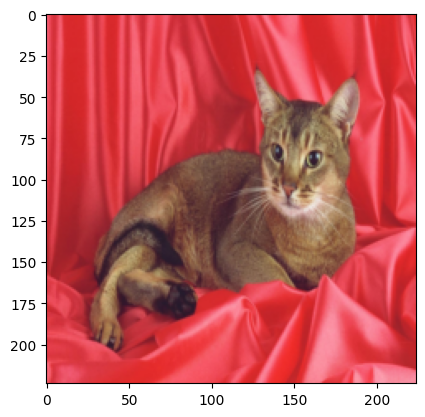

In [4]:
import matplotlib.pyplot as plt

print(set(labels))
print(images[0].shape)
image = images[0].permute(1,2,0)
plt.imshow(image)
len(test_dataset.classes)

print(f'train len : {len(train_loader)}')

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

class Net(nn.Module):
    def __init__(self):

        super().__init__()

        # strided encoder
        self.conv0 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1)
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1)
        self.global_pool = nn.AvgPool2d(kernel_size=14)

        # classifier head
        self.fc = nn.Linear(256, 37)

    def forward(self, x):
        x = F.relu(self.conv0(x))
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

In [ ]:
from torchinfo import summary
model = Net()
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model.train()
epochs = 10
losses = []

for epoch in range(epochs):
    loss = 0.0
    for imgs, labels in train_loader:
        optimizer.zero_grad()
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss += loss
        loss.backward()
        optimizer.step()
    print(f'loss after epoch {epoch} is {loss}')
    losses.append(loss / len(train_loader) / 32)


Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            448
├─Conv2d: 1-2                            4,640
├─Conv2d: 1-3                            18,496
├─Conv2d: 1-4                            73,856
├─Conv2d: 1-5                            295,168
├─AvgPool2d: 1-6                         --
├─Linear: 1-7                            9,509
Total params: 402,117
Trainable params: 402,117
Non-trainable params: 0
loss after epoch 0 is 3.612790822982788
loss after epoch 1 is 3.6110918521881104
loss after epoch 2 is 3.610111713409424
loss after epoch 3 is 3.6108944416046143
loss after epoch 4 is 3.61860728263855
loss after epoch 5 is 3.6111948490142822
loss after epoch 6 is 3.610236883163452
loss after epoch 7 is 3.614081382751465
loss after epoch 8 is 3.609496593475342
loss after epoch 9 is 3.613353729248047


## Add BarchNorm

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np

class Net(nn.Module):
    def __init__(self):

        super().__init__()

        # strided encoder
        self.conv0 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn0 = nn.BatchNorm2d(16)
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(256)
        self.global_pool = nn.AvgPool2d(kernel_size=14)

        # classifier head
        self.fc = nn.Linear(256, 37)

    def forward(self, x):
        x = F.relu(self.bn0(self.conv0(x)))
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x


def validate(test_loader, model, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for imgs, labels in test_loader:
            pred = model(imgs)
            test_loss = criterion(pred, labels)
            batch_size = imgs.size(0)
            total_loss += test_loss.item() * batch_size
            total_samples += batch_size
    return total_loss / total_samples



from torchinfo import summary
model = Net()
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 10
losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for imgs, labels in train_loader:
        optimizer.zero_grad()
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    val_loss = validate(test_loader, model, criterion)
    
    losses.append(epoch_train_loss)
    val_losses.append(val_loss)
    print(f'Epoch {epoch} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}')


Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            432
├─BatchNorm2d: 1-2                       32
├─Conv2d: 1-3                            4,608
├─BatchNorm2d: 1-4                       64
├─Conv2d: 1-5                            18,432
├─BatchNorm2d: 1-6                       128
├─Conv2d: 1-7                            73,728
├─BatchNorm2d: 1-8                       256
├─Conv2d: 1-9                            294,912
├─BatchNorm2d: 1-10                      512
├─AvgPool2d: 1-11                        --
├─Linear: 1-12                           9,509
Total params: 402,613
Trainable params: 402,613
Non-trainable params: 0
Epoch 0 | Train Loss: 3.5345 | Val Loss: 3.5179
Epoch 1 | Train Loss: 3.3982 | Val Loss: 3.4582
Epoch 2 | Train Loss: 3.2999 | Val Loss: 3.4099
Epoch 3 | Train Loss: 3.2241 | Val Loss: 3.4067
Epoch 4 | Train Loss: 3.1487 | Val Loss: 3.3518
Epoch 5 | Train Loss: 3.0690 | Val Loss: 3.2

## Weight decay applied

In [15]:

from torchinfo import summary
model = Net()
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-2)
epochs = 10
losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for imgs, labels in train_loader:
        optimizer.zero_grad()
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    val_loss = validate(test_loader, model, criterion)
    
    losses.append(epoch_train_loss)
    val_losses.append(val_loss)
    print(f'Epoch {epoch} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}')


Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            432
├─BatchNorm2d: 1-2                       32
├─Conv2d: 1-3                            4,608
├─BatchNorm2d: 1-4                       64
├─Conv2d: 1-5                            18,432
├─BatchNorm2d: 1-6                       128
├─Conv2d: 1-7                            73,728
├─BatchNorm2d: 1-8                       256
├─Conv2d: 1-9                            294,912
├─BatchNorm2d: 1-10                      512
├─AvgPool2d: 1-11                        --
├─Linear: 1-12                           9,509
Total params: 402,613
Trainable params: 402,613
Non-trainable params: 0
Epoch 0 | Train Loss: 3.5632 | Val Loss: 3.5312
Epoch 1 | Train Loss: 3.4794 | Val Loss: 3.5848
Epoch 2 | Train Loss: 3.4307 | Val Loss: 3.4684
Epoch 3 | Train Loss: 3.3842 | Val Loss: 3.6061
Epoch 4 | Train Loss: 3.3713 | Val Loss: 3.4772
Epoch 5 | Train Loss: 3.3622 | Val Loss: 3.4

# Normalize pixels

In [5]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np

class Net(nn.Module):
    def __init__(self):

        super().__init__()

        # strided encoder
        self.conv0 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn0 = nn.BatchNorm2d(16)
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(256)
        self.global_pool = nn.AvgPool2d(kernel_size=14)

        # classifier head
        self.fc = nn.Linear(256, 37)

    def forward(self, x):
        x = F.relu(self.bn0(self.conv0(x)))
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x


MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def normalize_batch(images):
    if images.max() > 1.0:
        images = images.float() / 255.0
    import torchvision.transforms.functional as F
    return F.normalize(images, mean=MEAN, std=STD)

def validate(test_loader, model, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = normalize_batch(imgs)
            pred = model(imgs)
            test_loss = criterion(pred, labels)
            batch_size = imgs.size(0)
            total_loss += test_loss.item() * batch_size
            total_samples += batch_size
    return total_loss / total_samples



from torchinfo import summary
model = Net()
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 30
losses = []
val_losses = []


for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for imgs, labels in train_loader:
        optimizer.zero_grad()
        imgs = normalize_batch(imgs)
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    val_loss = validate(test_loader, model, criterion)
    
    losses.append(epoch_train_loss)
    val_losses.append(val_loss)
    print(f'Epoch {epoch} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}')


Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            432
├─BatchNorm2d: 1-2                       32
├─Conv2d: 1-3                            4,608
├─BatchNorm2d: 1-4                       64
├─Conv2d: 1-5                            18,432
├─BatchNorm2d: 1-6                       128
├─Conv2d: 1-7                            73,728
├─BatchNorm2d: 1-8                       256
├─Conv2d: 1-9                            294,912
├─BatchNorm2d: 1-10                      512
├─AvgPool2d: 1-11                        --
├─Linear: 1-12                           9,509
Total params: 402,613
Trainable params: 402,613
Non-trainable params: 0
Epoch 0 | Train Loss: 3.5542 | Val Loss: 3.6522
Epoch 1 | Train Loss: 3.4425 | Val Loss: 3.5062
Epoch 2 | Train Loss: 3.3742 | Val Loss: 3.4384
Epoch 3 | Train Loss: 3.3093 | Val Loss: 3.4060
Epoch 4 | Train Loss: 3.2457 | Val Loss: 3.4111
Epoch 5 | Train Loss: 3.1885 | Val Loss: 3.3

losses len 30
losses len 30


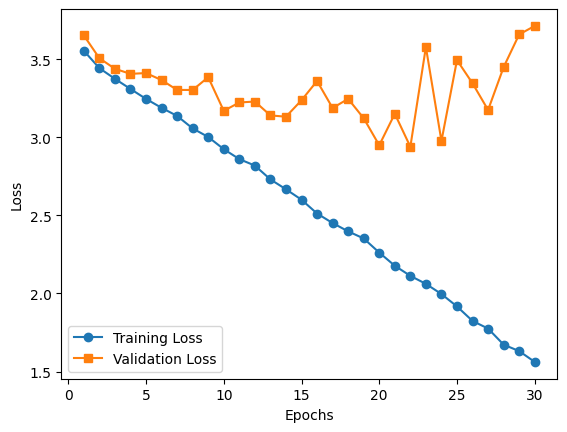

In [10]:
import matplotlib.pyplot as plt

print(f'losses len {len(losses)}')
print(f'losses len {len(val_losses)}')

epochs = range(1, len(losses) + 1)
plt.plot(epochs, losses, label='Training Loss', marker='o')
plt.plot(epochs, val_losses, label='Validation Loss', marker='s')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Add dropout

In [12]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np

class Net(nn.Module):
    def __init__(self):

        super().__init__()

        # strided encoder
        self.conv0 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn0 = nn.BatchNorm2d(16)
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(256)
        self.global_pool = nn.AvgPool2d(kernel_size=14)
        self.dropout = nn.Dropout(p=0.2)
        # classifier head
        self.fc = nn.Linear(256, 37)

    def forward(self, x):
        x = F.relu(self.bn0(self.conv0(x)))
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def normalize_batch(images):
    if images.max() > 1.0:
        images = images.float() / 255.0
    import torchvision.transforms.functional as F
    return F.normalize(images, mean=MEAN, std=STD)

def validate(test_loader, model, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = normalize_batch(imgs)
            pred = model(imgs)
            test_loss = criterion(pred, labels)
            batch_size = imgs.size(0)
            total_loss += test_loss.item() * batch_size
            total_samples += batch_size
    return total_loss / total_samples



from torchinfo import summary
model = Net()
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 30
losses = []
val_losses = []


for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for imgs, labels in train_loader:
        optimizer.zero_grad()
        imgs = normalize_batch(imgs)
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    val_loss = validate(test_loader, model, criterion)
    
    losses.append(epoch_train_loss)
    val_losses.append(val_loss)
    print(f'Epoch {epoch} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}')


Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            432
├─BatchNorm2d: 1-2                       32
├─Conv2d: 1-3                            4,608
├─BatchNorm2d: 1-4                       64
├─Conv2d: 1-5                            18,432
├─BatchNorm2d: 1-6                       128
├─Conv2d: 1-7                            73,728
├─BatchNorm2d: 1-8                       256
├─Conv2d: 1-9                            294,912
├─BatchNorm2d: 1-10                      512
├─AvgPool2d: 1-11                        --
├─Dropout: 1-12                          --
├─Linear: 1-13                           9,509
Total params: 402,613
Trainable params: 402,613
Non-trainable params: 0
Epoch 0 | Train Loss: 3.5665 | Val Loss: 3.5618
Epoch 1 | Train Loss: 3.4330 | Val Loss: 3.5242
Epoch 2 | Train Loss: 3.3658 | Val Loss: 3.4667
Epoch 3 | Train Loss: 3.3028 | Val Loss: 3.4252
Epoch 4 | Train Loss: 3.2403 | Val Loss: 3.4667


Increase the LR

Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            432
├─BatchNorm2d: 1-2                       32
├─Conv2d: 1-3                            4,608
├─BatchNorm2d: 1-4                       64
├─Conv2d: 1-5                            18,432
├─BatchNorm2d: 1-6                       128
├─Conv2d: 1-7                            73,728
├─BatchNorm2d: 1-8                       256
├─Conv2d: 1-9                            294,912
├─BatchNorm2d: 1-10                      512
├─AvgPool2d: 1-11                        --
├─Dropout: 1-12                          --
├─Linear: 1-13                           9,509
Total params: 402,613
Trainable params: 402,613
Non-trainable params: 0
Epoch 0 | Train Loss: 3.6619 | Val Loss: 3.6191
Epoch 1 | Train Loss: 3.5493 | Val Loss: 3.5842
Epoch 2 | Train Loss: 3.4996 | Val Loss: 3.5854
Epoch 3 | Train Loss: 3.4653 | Val Loss: 3.5363
Epoch 4 | Train Loss: 3.4322 | Val Loss: 3.5205


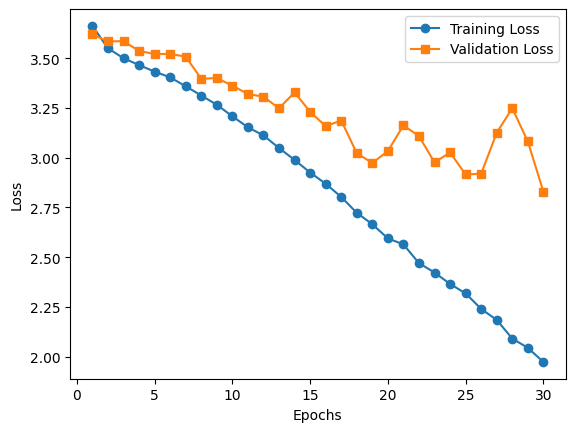

In [18]:
model = Net()
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=5e-3)
epochs = 30
losses = []
val_losses = []


for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for imgs, labels in train_loader:
        optimizer.zero_grad()
        imgs = normalize_batch(imgs)
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    val_loss = validate(test_loader, model, criterion)
    
    losses.append(epoch_train_loss)
    val_losses.append(val_loss)
    print(f'Epoch {epoch} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}')

epochs = range(1, len(losses) + 1)
print(f'losses: {losses}')
plt.plot(epochs, losses, label='Training Loss', marker='o')
plt.plot(epochs, val_losses, label='Validation Loss', marker='s')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Add transforms

In [20]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torchvision.transforms as T



mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

val_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

train_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=train_transforms,
    download=True,
)

test_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    transform=val_transforms,
    download=True,
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)



import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np

class Net(nn.Module):
    def __init__(self):

        super().__init__()

        # strided encoder
        self.conv0 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn0 = nn.BatchNorm2d(16)
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(256)
        self.global_pool = nn.AvgPool2d(kernel_size=14)
        self.dropout = nn.Dropout(p=0.2)
        # classifier head
        self.fc = nn.Linear(256, 37)

    def forward(self, x):
        x = F.relu(self.bn0(self.conv0(x)))
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


def validate(test_loader, model, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for imgs, labels in test_loader:
            pred = model(imgs)
            test_loss = criterion(pred, labels)
            batch_size = imgs.size(0)
            total_loss += test_loss.item() * batch_size
            total_samples += batch_size
    return total_loss / total_samples



from torchinfo import summary
model = Net()
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 30
losses = []
val_losses = []


for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for imgs, labels in train_loader:
        optimizer.zero_grad()
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    val_loss = validate(test_loader, model, criterion)
    
    losses.append(epoch_train_loss)
    val_losses.append(val_loss)
    print(f'Epoch {epoch} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}')


Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            432
├─BatchNorm2d: 1-2                       32
├─Conv2d: 1-3                            4,608
├─BatchNorm2d: 1-4                       64
├─Conv2d: 1-5                            18,432
├─BatchNorm2d: 1-6                       128
├─Conv2d: 1-7                            73,728
├─BatchNorm2d: 1-8                       256
├─Conv2d: 1-9                            294,912
├─BatchNorm2d: 1-10                      512
├─AvgPool2d: 1-11                        --
├─Dropout: 1-12                          --
├─Linear: 1-13                           9,509
Total params: 402,613
Trainable params: 402,613
Non-trainable params: 0
Epoch 0 | Train Loss: 3.5518 | Val Loss: 3.5514
Epoch 1 | Train Loss: 3.4415 | Val Loss: 3.5625
Epoch 2 | Train Loss: 3.3897 | Val Loss: 3.4449
Epoch 3 | Train Loss: 3.3178 | Val Loss: 3.4468
Epoch 4 | Train Loss: 3.2656 | Val Loss: 3.4303


losses: [3.5517906334089195, 3.44149633905162, 3.3897309634996495, 3.3178390440733536, 3.265581529036812, 3.2207056563833487, 3.140568847241609, 3.0581041543380074, 2.9888824421426525, 2.9071313940960426, 2.8402750471363896, 2.773546658391538, 2.709578101531319, 2.659714943429698, 2.6170170120570972, 2.5898106450619904, 2.546541099962981, 2.4735872942468395, 2.466389252828515, 2.393899825344915, 2.3459756592045657, 2.32397707545239, 2.2914468143297277, 2.2479033905526866, 2.2291364431381226, 2.1626978418101435, 2.16483096247134, 2.117860126495361, 2.07735145713972, 2.024374227938445]


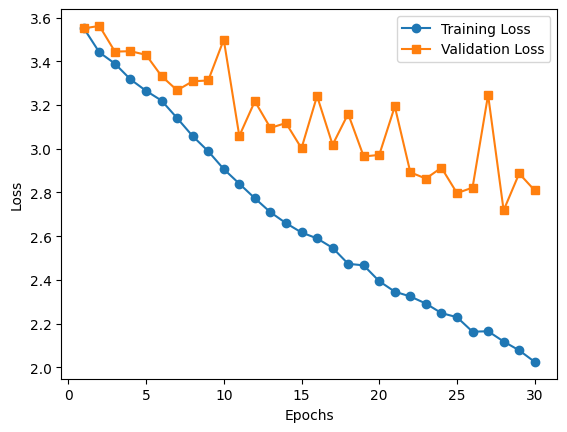

In [21]:
epochs = range(1, len(losses) + 1)
print(f'losses: {losses}')
plt.plot(epochs, losses, label='Training Loss', marker='o')
plt.plot(epochs, val_losses, label='Validation Loss', marker='s')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [23]:
print(f'the len of the trian set is : {len(train_loader) * 32}')
print(f'the len of the val set is {len(test_loader) * 32}')
images, labels = next(iter(train_loader))

print(f'images.shape : {images.shape}')

the len of the trian set is : 3680
the len of the val set is 3680
images.shape : torch.Size([32, 3, 224, 224])


## Use the gpu, forgot I have one

In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'device: {device}')

device: cuda


In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torchvision.transforms as T



mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

val_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

train_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=train_transforms,
    download=True,
)

test_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    transform=val_transforms,
    download=True,
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)



import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np

class Net(nn.Module):
    def __init__(self):

        super().__init__()

        # strided encoder
        self.conv0 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn0 = nn.BatchNorm2d(16)
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(256)
        self.global_pool = nn.AvgPool2d(kernel_size=14)
        self.dropout = nn.Dropout(p=0.2)
        # classifier head
        self.fc = nn.Linear(256, 37)

    def forward(self, x):
        x = F.relu(self.bn0(self.conv0(x)))
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


def validate(test_loader, model, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for imgs, labels in test_loader:

            imgs, labels = imgs.to(device), labels.to(device)
            pred = model(imgs)
            test_loss = criterion(pred, labels)
            batch_size = imgs.size(0)
            total_loss += test_loss.item() * batch_size
            total_samples += batch_size
    return total_loss / total_samples



from torchinfo import summary
model = Net()
model = model.to(device)
print(summary(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
lr_scheduler = optim.lr_scheduler.LRScheduler(optimizer, )
epochs = 30
losses = []
val_losses = []


for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * imgs.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    val_loss = validate(test_loader, model, criterion)
    
    losses.append(epoch_train_loss)
    val_losses.append(val_loss)
    print(f'Epoch {epoch} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}')


Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            432
├─BatchNorm2d: 1-2                       32
├─Conv2d: 1-3                            4,608
├─BatchNorm2d: 1-4                       64
├─Conv2d: 1-5                            18,432
├─BatchNorm2d: 1-6                       128
├─Conv2d: 1-7                            73,728
├─BatchNorm2d: 1-8                       256
├─Conv2d: 1-9                            294,912
├─BatchNorm2d: 1-10                      512
├─AvgPool2d: 1-11                        --
├─Dropout: 1-12                          --
├─Linear: 1-13                           9,509
Total params: 402,613
Trainable params: 402,613
Non-trainable params: 0
Epoch 0 | Train Loss: 3.5670 | Val Loss: 3.5572
Epoch 1 | Train Loss: 3.4485 | Val Loss: 3.5208
Epoch 2 | Train Loss: 3.3735 | Val Loss: 3.4304
Epoch 3 | Train Loss: 3.3238 | Val Loss: 3.5092
Epoch 4 | Train Loss: 3.2667 | Val Loss: 3.3753


losses: [3.5669763647991677, 3.448453824416451, 3.3734674743984057, 3.323806804159413, 3.2667049615279486, 3.2204511020494544, 3.1826277857241423, 3.119950526693593, 3.0562983305557916, 3.003920837070631, 2.9257176606551463, 2.886811229457026, 2.8190317610035773, 2.767022533002107, 2.709795734156733, 2.6652710313382357, 2.642778921127319, 2.568269744126693, 2.5366901065992273, 2.5305402175239893, 2.4904287535211314, 2.43038126696711, 2.410908213905666, 2.3774027689643527, 2.334888254041257, 2.314008952223736, 2.3151600951733795, 2.249888563156128, 2.197043112049932, 2.219785003040148]


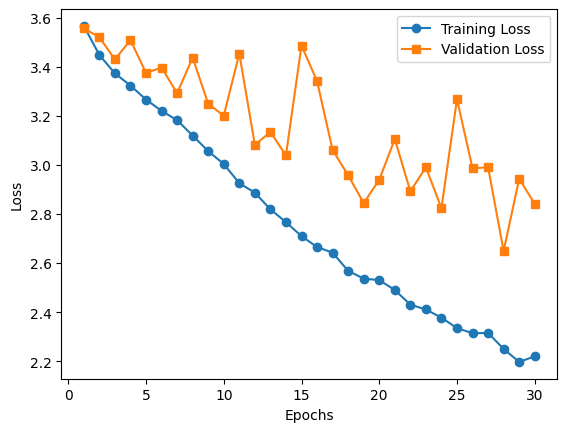

In [28]:
epochs = range(1, len(losses) + 1)
print(f'losses: {losses}')
plt.plot(epochs, losses, label='Training Loss', marker='o')
plt.plot(epochs, val_losses, label='Validation Loss', marker='s')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Add label_smoothing & lr scheduler

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torchvision.transforms as T



mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

val_transforms = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std)
])

train_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=train_transforms,
    download=True,
)

test_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    transform=val_transforms,
    download=True,
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)



import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np

class Net(nn.Module):
    def __init__(self):

        super().__init__()

        # strided encoder
        self.conv0 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn0 = nn.BatchNorm2d(16)
        self.conv1 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(256)
        self.global_pool = nn.AvgPool2d(kernel_size=14)
        self.dropout = nn.Dropout(p=0.2)
        # classifier head
        self.fc = nn.Linear(256, 37)

    def forward(self, x):
        x = F.relu(self.bn0(self.conv0(x)))
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x


def validate(test_loader, model, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for imgs, labels in test_loader:

            imgs, labels = imgs.to(device), labels.to(device)
            pred = model(imgs)
            test_loss = criterion(pred, labels)
            batch_size = imgs.size(0)
            total_loss += test_loss.item() * batch_size
            total_samples += batch_size
    return total_loss / total_samples



from torchinfo import summary
model = Net()
model = model.to(device)
print(summary(model))

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 30
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
losses = []
val_losses = []


for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        pred = model(imgs)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * imgs.size(0)

    scheduler.step()

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    val_loss = validate(test_loader, model, criterion)
    
    losses.append(epoch_train_loss)
    val_losses.append(val_loss)
    print(f'Epoch {epoch} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}')



Layer (type:depth-idx)                   Param #
Net                                      --
├─Conv2d: 1-1                            432
├─BatchNorm2d: 1-2                       32
├─Conv2d: 1-3                            4,608
├─BatchNorm2d: 1-4                       64
├─Conv2d: 1-5                            18,432
├─BatchNorm2d: 1-6                       128
├─Conv2d: 1-7                            73,728
├─BatchNorm2d: 1-8                       256
├─Conv2d: 1-9                            294,912
├─BatchNorm2d: 1-10                      512
├─AvgPool2d: 1-11                        --
├─Dropout: 1-12                          --
├─Linear: 1-13                           9,509
Total params: 402,613
Trainable params: 402,613
Non-trainable params: 0
Epoch 0 | Train Loss: 3.5660 | Val Loss: 3.5374
Epoch 1 | Train Loss: 3.4692 | Val Loss: 3.6623
Epoch 2 | Train Loss: 3.3919 | Val Loss: 3.5742
Epoch 3 | Train Loss: 3.3206 | Val Loss: 3.4292
Epoch 4 | Train Loss: 3.2655 | Val Loss: 3.4224
